# 01 — Khám phá dữ liệu NASA PCoE

Bốn cell Li-ion 18650 dung lượng danh định 2,0 Ah (B0005, B0006, B0007, B0018), chạy sạc CC-CV và xả CC 2 A ở 24°C đến khi dung lượng giảm 30% (README của bộ dữ liệu, SRC-016).

**SoH** = dung lượng xả / 2,0 Ah × 100.

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import soh_pipeline as S
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e4e3df'})
COL = {'B0005': '#2a78d6', 'B0006': '#eb6834', 'B0007': '#1baf7a', 'B0018': '#6250d6'}
df = S.dataset()
df.groupby('cell').agg(chu_ky=('full_cycles', 'max'), soh_dau=('soh', 'first'), soh_cuoi=('soh', 'last')).round(1)

,chu_ky,soh_dau,soh_cuoi
cell,,,
B0005,168,92.4,66.3
B0006,168,99.0,59.3
B0007,168,94.0,71.6
B0018,132,92.8,67.1


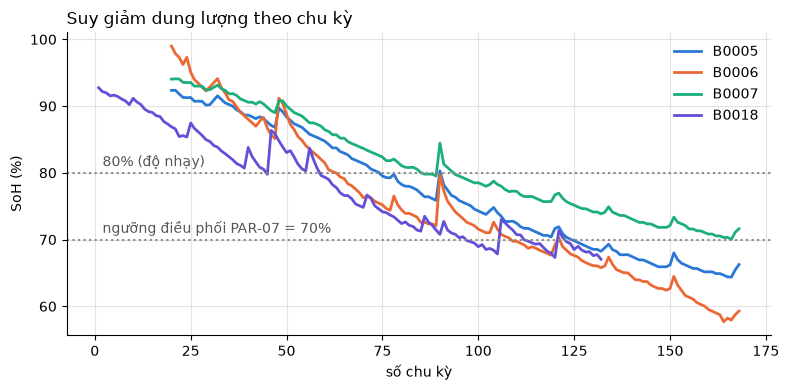

In [2]:
fig, ax = plt.subplots()
for c, g in df.groupby('cell'):
    ax.plot(g.full_cycles, g.soh, color=COL[c], lw=2, label=c)
ax.axhline(70, color='#888', ls=':'); ax.text(2, 71, 'ngưỡng điều phối PAR-07 = 70%', color='#555')
ax.axhline(80, color='#888', ls=':'); ax.text(2, 81, '80% (độ nhạy)', color='#555')
ax.set_xlabel('số chu kỳ'); ax.set_ylabel('SoH (%)'); ax.set_title('Suy giảm dung lượng theo chu kỳ', loc='left'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('../outputs/fig-fade.png', dpi=150); plt.show()

**Quan sát.** Dung lượng giảm gần tuyến tính, có các bước hồi phục ngắn sau thời gian nghỉ. Các cell dừng ở quanh 70% SoH, nên dữ liệu **ít điểm dưới 70%** — hạn chế cho bài toán quyết định ở ngưỡng 70%.